# Stock price forecasting using LOB

Before start, we need to test some libraries in order to build a reasonable dataset for the neural network architecture. Test will be focused on libraries for crypto market data and stock market data. For more corporate indices (bank indices) maybe there are other libraries to test in a second moment.

### Import modules

In [1]:
import os
import sys
import time 
import pandas
import random
import pickle
from tqdm import tqdm
import numpy as np

# ML
import pandas as pd
from matplotlib import pyplot as plt
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.preprocessing import LabelBinarizer, OneHotEncoder

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import json, argparse
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import build_timeseries
import LSTM
import utils
import CNN_LSTM

### Load LOB data

In [2]:
dataset = pd.read_parquet('./FI-2010/WRT1V/WRT1V_10.parquet', engine='pyarrow')
dataset = dataset[:]
# compute the price with the 1st level of the LOB and add the column to the dataset
#dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
#dataset['weighted_price'] = (dataset['P_Ask_1']*dataset['V_Ask_1'] + dataset['P_Bid_1']*dataset['V_Bid_1']) / (dataset['V_Ask_1']+dataset['V_Bid_1'])
#target_columns = dataset['Label'].astype(int)
dataset = dataset.drop('Label', axis=1)
dataset = dataset.drop('Day', axis=1)
display(dataset)

#plt.figure(figsize=(24,12))
#plt.plot(dataset['mid_price'])
#plt.show()

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_8,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,1.242047,-0.349285,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147150,1.462738,-0.030648,1.467926,-0.197623,1.462118,-0.401187,1.465580,-0.569871,1.461516,-0.004800,...,1.467151,-0.607661,1.456363,-0.413108,1.467757,-0.148597,1.454553,-0.422392,1.469532,-0.239478
147151,1.462738,-0.030648,1.467926,-0.197623,1.462118,-0.401187,1.465580,-0.623560,1.461516,-0.004800,...,1.467151,-0.607661,1.456363,-0.413108,1.467757,-0.148597,1.454553,-0.422392,1.469532,-0.239478
147152,1.462738,-0.030648,1.467926,-0.197623,1.462118,-0.401187,1.465580,-0.677249,1.461516,-0.004800,...,1.468135,-0.483058,1.456363,-0.413108,1.469725,-0.516647,1.454553,-0.422392,1.470517,-0.186564
147153,1.462738,-0.030648,1.467926,-0.197623,1.462118,-0.401187,1.466562,-0.737917,1.461516,-0.004800,...,1.468135,-0.483058,1.456363,-0.413108,1.469725,-0.516647,1.454553,-0.422392,1.470517,-0.186564


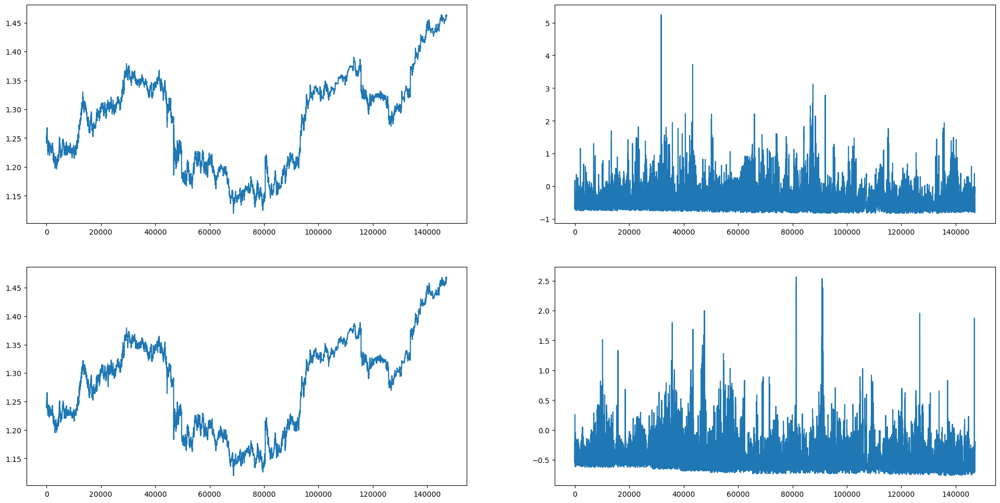

In [3]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(dataset['P_Ask_1'])
axs[0,1].plot(dataset['V_Ask_1'])
axs[1,0].plot(dataset['P_Bid_1'])
axs[1,1].plot(dataset['V_Bid_1'])
plt.show()

In [4]:
# The StandardScaler scales (to unit variance and removing the mean) 
# each feature column -> features processing
scaler = preprocessing.StandardScaler()
scaler.set_output(transform = 'pandas')
dataset = scaler.fit_transform(dataset)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_8,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10
0,-0.466939,-0.462450,-0.493986,0.138965,-0.473087,-0.408364,-0.488686,0.165905,-0.479343,-0.418088,...,-0.478570,0.528505,-0.490516,-0.443144,-0.465149,-0.546605,-0.514269,-0.686592,-0.461417,0.826112
1,-0.479363,-0.649813,-0.493986,-0.335214,-0.485507,-0.408364,-0.488686,-0.292442,-0.491759,-0.418088,...,-0.453926,-0.145330,-0.540213,-0.419182,-0.452852,0.471973,-0.551585,1.210432,-0.436876,-0.452989
2,-0.479363,-0.649813,-0.493986,0.055057,-0.485507,-0.408364,-0.488686,-0.292442,-0.491759,-0.418088,...,-0.453926,-0.145330,-0.540213,-0.419182,-0.452852,0.471973,-0.551585,1.210432,-0.436876,-0.452989
3,-0.479363,-0.649813,-0.493986,-0.272770,-0.485507,-0.408364,-0.488686,0.165905,-0.491759,-0.418088,...,-0.453926,-0.145330,-0.540213,-0.419182,-0.452852,0.471973,-0.551585,1.210432,-0.436876,-0.452989
4,-0.479363,-0.649813,-0.493986,-0.272770,-0.485507,-0.408364,-0.488686,0.165905,-0.491759,-0.418088,...,-0.453926,-0.145330,-0.540213,-0.419182,-0.452852,0.471973,-0.551585,1.210432,-0.436876,-0.452989
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147150,2.214236,1.166891,2.257022,1.230798,2.208157,0.431961,2.227430,-0.109346,2.201530,2.750460,...,2.229386,-0.800136,2.163486,-0.399986,2.228220,1.692541,2.152294,-0.494349,2.239907,1.115684
147151,2.214236,1.166891,2.257022,1.230798,2.208157,0.431961,2.227430,-0.366454,2.201530,2.750460,...,2.229386,-0.800136,2.163486,-0.399986,2.228220,1.692541,2.152294,-0.494349,2.239907,1.115684
147152,2.214236,1.166891,2.257022,1.230798,2.208157,0.431961,2.227430,-0.623562,2.201530,2.750460,...,2.241218,-0.159392,2.163486,-0.399986,2.251836,-0.655433,2.152294,-0.494349,2.251692,1.512138
147153,2.214236,1.166891,2.257022,1.230798,2.208157,0.431961,2.239290,-0.914094,2.201530,2.750460,...,2.241218,-0.159392,2.163486,-0.399986,2.251836,-0.655433,2.152294,-0.494349,2.251692,1.512138


### Create the effective time-series dataset, and the batch-iterators to process tensors

The procedure is the sliding window procedure

In [5]:
#device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# the final time-series dataset
lookback_period = 100
offset = 1
# Remember to reshape the arrays in order to get the correct tensor structure for convolution: [batch, channels, height, width]
# The standard tensor structure for LSTM layers is [batch, lookback_period, number of features] = [batch, height, width]
Dataset  =  build_timeseries.SlidingWindowDataset(	raw_dataset = dataset,
													split_rate = 0.7,
													#target_columns = target_columns,
													#target_columns = ['mid_price'],
													target_columns = ['P_Ask_1'],
													#target_columns = ['P_Ask_1', 'V_Ask_1', 'P_Bid_1', 'V_Bid_1'],
													lookback_period = lookback_period,
													offset = offset,
													channels = False
												)
# in the following lines the features are transformed into torch tensors, within the train and test loaders
trainset =  build_timeseries.CreateLoader(dataset = Dataset.train, transform = None)
testset  =  build_timeseries.CreateLoader(dataset = Dataset.valid, transform = None)
print('Tabelle nel trainset:', len(trainset))
print('Tabelle nel testset :', len(testset))

# dataloaders -> the batch dimension is added as first
trainloader = torch.utils.data.DataLoader(dataset=trainset, batch_size=32, shuffle=True, drop_last=False)
testloader  = torch.utils.data.DataLoader(dataset=testset,  batch_size=32, shuffle=True, drop_last=False)
print(next(iter(trainloader))[0].shape, next(iter(trainloader))[1].shape)
#display(pd.DataFrame(next(iter(trainloader))[0][0]))
#display(pd.DataFrame(next(iter(trainloader))[1][0]))

Tabelle nel trainset: 102938
Tabelle nel testset : 44117
torch.Size([32, 100, 40]) torch.Size([32, 1])


### Select the model and train it

In [6]:
W, H = len(dataset.columns), len(dataset)

model = LSTM.LSTM1(input_size=W, hidden_layer_size=64, num_layers=2, output_size=1, dropout=0.2)
#model = LSTM.LSTM2(input_size=W, hidden_layer_size=64, num_layers=2, output_size=1, dropout=0.2)
#model = LSTM.LSTMWithAttention(  input_size=W, 
#                                 encoder_hidden_size=64, 
#                                 encoder_layers=2, 
#                                 decoder_hidden_size=64, 
#                                 decoder_layers=2,
#                                 output_size=1,
#                                 dropout=0.2)

#model = CNN_LSTM.LobCNN(lookback_period = lookback_period,
#                        inner_convolutional_layers = 2,
#                        smoothing_percentage = 0.06,
#                        convolution_channels = 32,
#                        inception_channels = 64,
#                        lstm_layers = 1,
#                        output_size = 3,
#                        regression = False
#                    )

In [7]:
model.to(model.device)
learning_rate = 0.001
epochs = 3
#LOSS = nn.CrossEntropyLoss()
LOSS = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

training_info = utils.batch_gd( model_id=f'{model.name}-{offset}-FI-reg',
                                model=model,
                                criterion=LOSS, 
                                optimizer=optimizer, 
                                trainloader=trainloader, 
                                testloader=testloader, 
                                epochs=epochs,
                                regression=True, # integrate in model's fields
                                save=False)

Start training...

[--------------------------------------------------] 0.0%  starting epoch 1
Duration of training epoch 1: 236.03715229034424, seconds
Epoch 1/3, Train Loss: 0.00509272, Train Accuracy:  0.99232569, Validation Loss: 0.09196069, Validation Accuracy:  0.75648379, 
[=================---------------------------------] 33.3%  starting epoch 2
Duration of training epoch 2: 136.58228969573975, seconds
Epoch 2/3, Train Loss: 0.00240926, Train Accuracy:  0.99642555, Validation Loss: 0.05130002, Validation Accuracy:  0.86450905, 
[=================================-----------------] 66.7%  starting epoch 3
Duration of training epoch 3: 192.84389448165894, seconds
Epoch 3/3, Train Loss: 0.00219448, Train Accuracy:  0.99674185, Validation Loss: 0.04991194, Validation Accuracy:  0.86821091, 


PRINT LOSS FUNCTION, AND THE ACTUAL VS PREDICTED PRICE FOR TRAIN AND TEST SETS

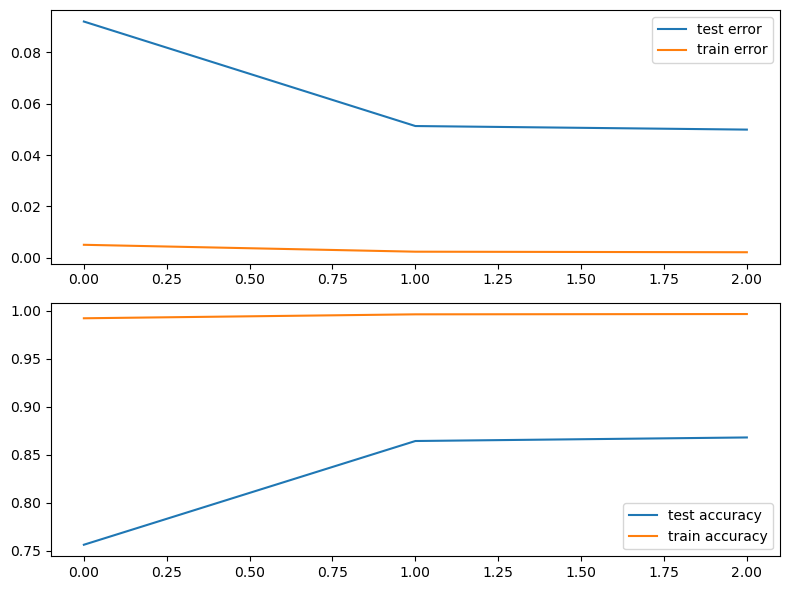

In [8]:
epochs_list = list(range(0,epochs))
_, axs = plt.subplots(2, 1, figsize=(8,6))
axs[0].plot(epochs_list, training_info['test_loss'],  label = "test error")
axs[0].plot(epochs_list, training_info['train_loss'], label = "train error")
axs[0].legend(loc = 'best')
axs[1].plot(epochs_list, training_info['test_accuracy'],  label = "test accuracy")
axs[1].plot(epochs_list, training_info['train_accuracy'], label = "train accuracy")
axs[1].legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-{offset}-FI-reg-LOSS.png')
plt.show()

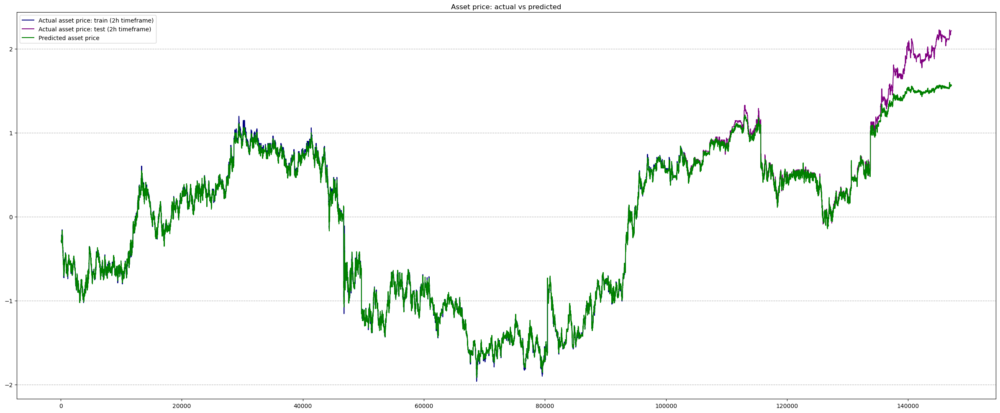

In [9]:
with torch.no_grad():
    out = list(range(len(Dataset.complete)))
    features = list(range(len(Dataset.complete)))
    for i in range(len(Dataset.complete)):
        features[i] = torch.Tensor(Dataset.complete[i][0])
        features[i] = torch.unsqueeze(features[i], axis = 0)
        features[i] = features[i].to(model.device)
        out[i] = model(features[i]).cpu().squeeze().numpy()

#targets = dataset[lookback_period:]['mid_price']
targets = dataset[lookback_period:]['P_Ask_1']
#targets = targets[lookback_period:]

plt.figure(figsize=(24, 10))
plt.plot(targets[:int(len(targets)*0.7)], label = "Actual asset price: train (2h timeframe)", color = "navy")
plt.plot(targets[int(len(targets)*0.7):], label = "Actual asset price: test (2h timeframe)", color = "purple")
plt.plot(list(range(lookback_period-1+offset,H)), out, label = "Predicted asset price", color = "green")
plt.title("Asset price: actual vs predicted")
plt.grid(visible=None, which='major', axis='y', linestyle='--')
plt.legend(loc = 'best', prop={'size': 10})
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-{offset}-FI-reg-PRYCE.png')
plt.show()

fig = go.Figure()
fig.add_scatter(y=targets[:int(len(targets)*0.7)], mode='lines', name= "Actual asset price: train", line_color = "navy")
fig.add_scatter(x=list(range(int(len(targets)*0.7), int(len(targets)))), y=targets[int(len(targets)*0.7):], mode='lines', name= "Actual asset price: test",  line_color = "purple")
fig.add_scatter(x=list(range(lookback_period,H)), y=out, mode='lines', name= "Predicted asset price", line_color = "green")
fig.write_html(f'./figures/{model.name}-{offset}-FI-reg-pryce.html')
fig.show()

In [10]:
#device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# the final time-series dataset
lookback_period = 100
offset = 10
# Remember to reshape the arrays in order to get the correct tensor structure for convolution: [batch, channels, height, width]
# The standard tensor structure for LSTM layers is [batch, lookback_period, number of features] = [batch, height, width]
Dataset  =  build_timeseries.SlidingWindowDataset(	raw_dataset = dataset,
													split_rate = 0.7,
													#target_columns = target_columns,
													#target_columns = ['mid_price'],
													target_columns = ['P_Ask_1'],
													#target_columns = ['P_Ask_1', 'V_Ask_1', 'P_Bid_1', 'V_Bid_1'],
													lookback_period = lookback_period,
													offset = offset,
													channels = False
												)
# in the following lines the features are transformed into torch tensors, within the train and test loaders
trainset =  build_timeseries.CreateLoader(dataset = Dataset.train, transform = None)
testset  =  build_timeseries.CreateLoader(dataset = Dataset.valid, transform = None)
print('Tabelle nel trainset:', len(trainset))
print('Tabelle nel testset :', len(testset))

# dataloaders -> the batch dimension is added as first
trainloader = torch.utils.data.DataLoader(dataset=trainset, batch_size=32, shuffle=True, drop_last=False)
testloader  = torch.utils.data.DataLoader(dataset=testset,  batch_size=32, shuffle=True, drop_last=False)
print(next(iter(trainloader))[0].shape, next(iter(trainloader))[1].shape)
#display(pd.DataFrame(next(iter(trainloader))[0][0]))
#display(pd.DataFrame(next(iter(trainloader))[1][0]))

Tabelle nel trainset: 102932
Tabelle nel testset : 44114
torch.Size([32, 100, 40]) torch.Size([32, 1])


In [11]:
W, H = len(dataset.columns), len(dataset)

model = LSTM.LSTM1(input_size=W, hidden_layer_size=64, num_layers=2, output_size=1, dropout=0.2)
#model = LSTM.LSTM2(input_size=W, hidden_layer_size=64, num_layers=2, output_size=1, dropout=0.2)
#model = LSTM.LSTMWithAttention(  input_size=W, 
#                                 encoder_hidden_size=64, 
#                                 encoder_layers=2, 
#                                 decoder_hidden_size=64, 
#                                 decoder_layers=2,
#                                 output_size=1,
#                                 dropout=0.2)

#model = CNN_LSTM.LobCNN(lookback_period = lookback_period,
#                        inner_convolutional_layers = 2,
#                        smoothing_percentage = 0.06,
#                        convolution_channels = 32,
#                        inception_channels = 64,
#                        lstm_layers = 1,
#                        output_size = 3,
#                        regression = False
#                    )

In [12]:
model.to(model.device)
learning_rate = 0.001
epochs = 3
#LOSS = nn.CrossEntropyLoss()
LOSS = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

training_info = utils.batch_gd( model_id=f'{model.name}-{offset}-FI-reg',
                                model=model,
                                criterion=LOSS, 
                                optimizer=optimizer, 
                                trainloader=trainloader, 
                                testloader=testloader, 
                                epochs=epochs,
                                regression=True, # integrate in model's fields
                                save=False)

Start training...

[--------------------------------------------------] 0.0%  starting epoch 1
Duration of training epoch 1: 265.65656542778015, seconds
Epoch 1/3, Train Loss: 0.00655367, Train Accuracy:  0.99023576, Validation Loss: 0.06120260, Validation Accuracy:  0.83821296, 
[=================---------------------------------] 33.3%  starting epoch 2
Duration of training epoch 2: 186.42331171035767, seconds
Epoch 2/3, Train Loss: 0.00289842, Train Accuracy:  0.99569500, Validation Loss: 0.07873501, Validation Accuracy:  0.79109115, 
[=================================-----------------] 66.7%  starting epoch 3
Duration of training epoch 3: 146.72444248199463, seconds
Epoch 3/3, Train Loss: 0.00268743, Train Accuracy:  0.99598927, Validation Loss: 0.04998158, Validation Accuracy:  0.86802320, 


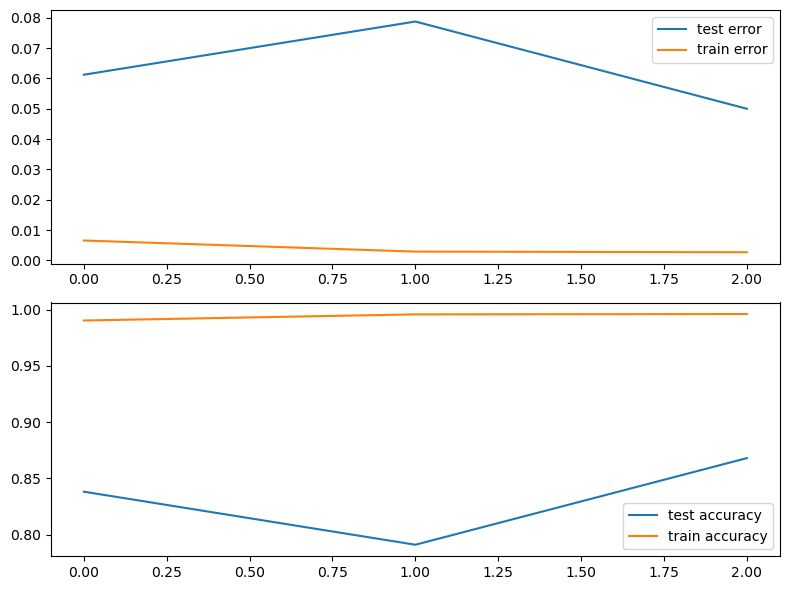

In [13]:
epochs_list = list(range(0,epochs))
_, axs = plt.subplots(2, 1, figsize=(8,6))
axs[0].plot(epochs_list, training_info['test_loss'],  label = "test error")
axs[0].plot(epochs_list, training_info['train_loss'], label = "train error")
axs[0].legend(loc = 'best')
axs[1].plot(epochs_list, training_info['test_accuracy'],  label = "test accuracy")
axs[1].plot(epochs_list, training_info['train_accuracy'], label = "train accuracy")
axs[1].legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-{offset}-FI-reg-LOSS.png')
plt.show()

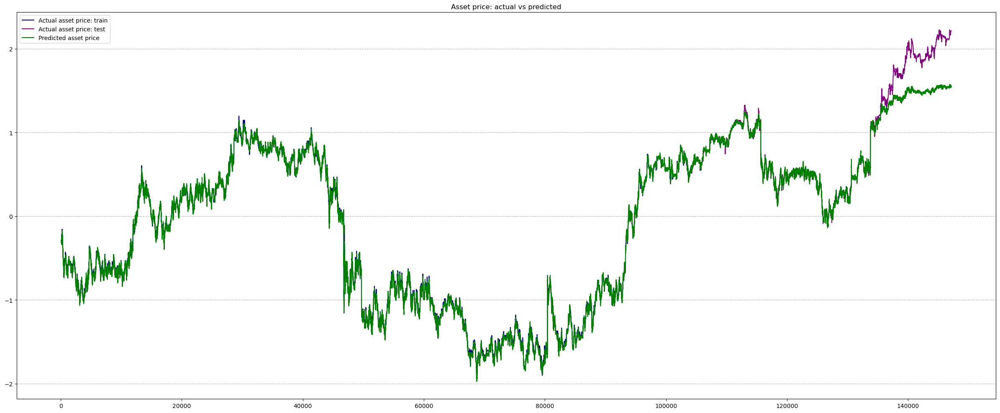

In [15]:
with torch.no_grad():
    out = list(range(len(Dataset.complete)))
    features = list(range(len(Dataset.complete)))
    for i in range(len(Dataset.complete)):
        features[i] = torch.Tensor(Dataset.complete[i][0])
        features[i] = torch.unsqueeze(features[i], axis = 0)
        features[i] = features[i].to(model.device)
        out[i] = model(features[i]).cpu().squeeze().numpy()

#targets = dataset[lookback_period:]['mid_price']
targets = dataset[lookback_period:]['P_Ask_1']
#targets = targets[lookback_period:]

plt.figure(figsize=(24, 10))
plt.plot(targets[:int(len(targets)*0.7)], label = "Actual asset price: train", color = "navy")
plt.plot(targets[int(len(targets)*0.7):], label = "Actual asset price: test", color = "purple")
plt.plot(list(range(lookback_period-1+offset,H)), out, label = "Predicted asset price", color = "green")
plt.title("Asset price: actual vs predicted")
plt.grid(visible=None, which='major', axis='y', linestyle='--')
plt.legend(loc = 'best', prop={'size': 10})
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-{offset}-FI-reg-PRYCE.png')
plt.show()

fig = go.Figure()
fig.add_scatter(y=targets[:int(len(targets)*0.7)], mode='lines', name= "Actual asset price: train", line_color = "navy")
fig.add_scatter(x=list(range(int(len(targets)*0.7), int(len(targets)))), y=targets[int(len(targets)*0.7):], mode='lines', name= "Actual asset price: test",  line_color = "purple")
fig.add_scatter(x=list(range(lookback_period-1+offset,H)), y=out, mode='lines', name= "Predicted asset price", line_color = "green")
fig.write_html(f'./figures/{model.name}-{offset}-FI-reg-pryce.html')
fig.show()